# IMDb Sentiment Analysis using DistilBERT + TensorFlow

Fine-tune a pretrained **DistilBERT** model for binary movie-review sentiment classification using **TensorFlow/Keras through KerasHub**.

This notebook keeps the workflow straightforward:
1. Load IMDb reviews
2. Prepare a manageable train/validation/test sample
3. Load pretrained DistilBERT and its tokenizer/preprocessor
4. Fine-tune the classifier
5. Evaluate with standard classification metrics
6. Inspect misclassified reviews and high-confidence errors
7. Compare against a TF-IDF + Logistic Regression baseline, and choose a decision threshold on validation data

**Framework:** TensorFlow + KerasHub  
**Pretrained model:** `distil_bert_base_en_uncased`  
**Dataset:** IMDb movie reviews  
**Task:** Positive / negative sentiment classification

> This is a TensorFlow implementation. It does not use PyTorch or Hugging Face Trainer.

## 1. Install dependencies

Run once in a fresh environment. A GPU runtime (Google Colab T4, if available) is strongly recommended for fine-tuning DistilBERT.

In [20]:

%pip install -q --upgrade tensorflow keras-hub tensorflow-datasets scikit-learn pandas matplotlib

## 2. Imports and configuration

We use a short sequence length and a subset of the dataset to keep the experiment manageable. The held-out test sample is not used for training or validation.

In [21]:

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
import keras_hub

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_auc_score,
)

SEED = 42
MAX_LENGTH = 256
BATCH_SIZE = 16
EPOCHS = 2
LEARNING_RATE = 2e-5
THRESHOLD = 0.5

TRAIN_SAMPLES = 8000
TEST_SAMPLES = 5000

OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)
print("KerasHub:", keras_hub.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.21.0
Keras: 3.15.1
KerasHub: 0.33.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load the IMDb dataset

The IMDb dataset is loaded with Keras (`keras.datasets.imdb`). It downloads automatically on the first run; no manual CSV download is required.

- 25,000 labelled training reviews
- 25,000 labelled test reviews
- Label `0` = negative, `1` = positive

Keras stores each review as a list of word indices, so the cell below converts them back to text for the DistilBERT tokenizer. The rebuilt text is lowercase and has no punctuation.

We use a stratified subset for a quicker first experiment. Increase `TRAIN_SAMPLES` and `TEST_SAMPLES` later if you have enough GPU time.

In [22]:
!pip install importlib_resources

In [23]:
import numpy as np
import keras

print("Loading IMDb dataset via Keras...")
# Load pre-tokenized indices from Keras
(train_data, train_label_all), (test_data, test_label_all) = keras.datasets.imdb.load_data()

# Convert indices back to text reviews so your downstream tokenizer (DistilBERT) can process them
word_index = keras.datasets.imdb.get_word_index()
reverse_word_index = {value: key for key, value in word_index.items()}

def decode_review(text_ids):
    # Note that the indices are offset by 3 because 0, 1, and 2 are reserved
    # for "padding", "start of sequence", and "unknown".
    return " ".join([reverse_word_index.get(i - 3, "?") for i in text_ids])

print("Decoding train reviews...")
train_text_all = np.array([decode_review(seq).encode('utf-8') for seq in train_data], dtype=object)

print("Decoding test reviews...")
test_text_all = np.array([decode_review(seq).encode('utf-8') for seq in test_data], dtype=object)

print("Full training set:", len(train_text_all))
print("Full test set:", len(test_text_all))

Loading IMDb dataset via Keras...
Decoding train reviews...
Decoding test reviews...
Full training set: 25000
Full test set: 25000


## 4. Create train, validation and test samples

We create a stratified validation split from the training portion. The official test split remains separate.

In [24]:
# Stratified subset from the official training split
x_train, _, y_train, _ = train_test_split(
    train_text_all,
    train_label_all,
    train_size=TRAIN_SAMPLES,
    random_state=SEED,
    stratify=train_label_all,
)

x_train, x_val, y_train, y_val = train_test_split(
    x_train,
    y_train,
    test_size=0.2,
    random_state=SEED,
    stratify=y_train,
)

# Stratified sample from the official test split
x_test, _, y_test, _ = train_test_split(
    test_text_all,
    test_label_all,
    train_size=TEST_SAMPLES,
    random_state=SEED,
    stratify=test_label_all,
)

print("Train:", len(x_train))
print("Validation:", len(x_val))
print("Test:", len(x_test))
print("Example review:", x_train[0].decode("utf-8")[:500])
print("Example label:", "Positive" if y_train[0] == 1 else "Negative")

Train: 6400
Validation: 1600
Test: 5000
Example review: ? zabriskie point 1970 this was especially interesting to me on a personal level since it takes place under identical circumstances with identical peers in my own life  the counter culture movement of the late 60's early 70's on and off campus we follow two unrelated young people in separate stories who are slowly woven together one is a young man in los angeles tired of all the endless pseudo revolutionary jabber in the classrooms and lunchrooms of his campus and the other a young woman drivin
Example label: Positive


## 4.1 Baseline: TF-IDF + Logistic Regression

Before fine-tuning a Transformer, we train a classic baseline so DistilBERT's result has something to be compared against.

- TF-IDF turns each review into weighted word / bigram counts
- Logistic Regression classifies from those features
- It trains in seconds on CPU, and uses the **same** train / validation / test samples as DistilBERT

Note: the baseline sees the full review, while DistilBERT only sees the first 128 tokens. This is a real difference between the two setups, so keep it in mind when comparing.

In [25]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_score, recall_score, f1_score

def to_str(arr):
    return [t.decode("utf-8") for t in arr]

def compute_metrics(y_true, prob, threshold=0.5):
    """Metrics for the positive class, plus negative-class recall (the weaker class here)."""
    pred = (np.asarray(prob) >= threshold).astype(int)
    return {
        "threshold": round(float(threshold), 3),
        "accuracy": accuracy_score(y_true, pred),
        "precision": precision_score(y_true, pred, zero_division=0),
        "recall": recall_score(y_true, pred, zero_division=0),
        "f1": f1_score(y_true, pred, zero_division=0),
        "negative_recall": recall_score(y_true, pred, pos_label=0, zero_division=0),
        "roc_auc": roc_auc_score(y_true, prob),
    }

tfidf = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), min_df=2, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(to_str(x_train))   # fit on training data only

baseline = LogisticRegression(max_iter=1000)
baseline.fit(X_train_tfidf, y_train)

baseline_val_prob = baseline.predict_proba(tfidf.transform(to_str(x_val)))[:, 1]
baseline_test_prob = baseline.predict_proba(tfidf.transform(to_str(x_test)))[:, 1]

baseline_test_metrics = compute_metrics(y_test, baseline_test_prob)
print("TF-IDF + Logistic Regression (test):")
for k, v in baseline_test_metrics.items():
    print(f"  {k}: {v:.4f}")

TF-IDF + Logistic Regression (test):
  threshold: 0.5000
  accuracy: 0.8812
  precision: 0.8740
  recall: 0.8908
  f1: 0.8823
  negative_recall: 0.8716
  roc_auc: 0.9525


## 5. Load pretrained DistilBERT

KerasHub provides a pretrained DistilBERT text-classification model and its text preprocessor. The preprocessor handles tokenization, special tokens, truncation and padding.

We attach a two-class classification head and fine-tune the pretrained model on IMDb.

In [26]:
PRESET = "distil_bert_base_en_uncased"

preprocessor = keras_hub.models.DistilBertTextClassifierPreprocessor.from_preset(
    PRESET,
    sequence_length=MAX_LENGTH,
)

model = keras_hub.models.DistilBertTextClassifier.from_preset(
    PRESET,
    num_classes=2,
    preprocessor=preprocessor,
)

model.summary()

Preprocessor: "distil_bert_text_classifier_preprocessor_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                                                  ┃                                   Config ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ distil_bert_tokenizer (DistilBertTokenizer)                   │                       Vocab size: 30,522 │
└───────────────────────────────────────────────────────────────┴──────────────────────────────────────────┘

Model: "distil_bert_text_classifier_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ padding_mask (InputLayer)     │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ token_ids (InputLayer)        │ (None, None)              │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ distil_bert_backbone          │ (None, None, 768)         │      66,362,880 │ padding_mask[0][0],        │
│ (DistilBertBackbone)          │                           │                 │ token_ids[0][0]            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ get_item_1 (GetItem)          │ (None, 768)               │               0 │ distil_bert_backbone[0][0] │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ pooled_dense (Dense)          │ (None, 768)               │         590,592 │ get_item_1[0][0]           │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ output_dropout (Dropout)      │ (None, 768)               │               0 │ pooled_dense[0][0]         │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ logits (Dense)                │ (None, 2)                 │           1,538 │ output_dropout[0][0]       │
└───────────────────────────────┴───────────────────────────┴─────────────────┴────────────────────────────┘

 Total params: 66,955,010 (255.41 MB)

 Trainable params: 66,955,010 (255.41 MB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model

The model returns class logits, so we use sparse categorical cross-entropy with `from_logits=True`. A small learning rate is typical when fine-tuning a pretrained Transformer.

In [27]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=[keras.metrics.SparseCategoricalAccuracy(name="accuracy")],
)

## 7. Fine-tune DistilBERT

We train for two epochs with early stopping. Fine-tuning a Transformer is computationally heavier than training a small LSTM, so use a GPU runtime when possible.

In [28]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=1,
    restore_best_weights=True,
)

history = model.fit(
    x=x_train,
    y=y_train,
    validation_data=(x_val, y_val),
    batch_size=BATCH_SIZE,
    epochs=EPOCHS,
    callbacks=[early_stopping],
    verbose=1,
)

/usr/local/lib/python3.13/dist-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a grain dataset. The grain dataset is expected to already be shuffled.
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/2
400/400 ━━━━━━━━━━━━━━━━━━━━ 218s 442ms/step - accuracy: 0.8395 - loss: 0.3656 - val_accuracy: 0.8875 - val_loss: 0.2813
Epoch 2/2
400/400 ━━━━━━━━━━━━━━━━━━━━ 170s 426ms/step - accuracy: 0.9273 - loss: 0.1969 - val_accuracy: 0.8813 - val_loss: 0.3056


## 8. Plot training and validation curves

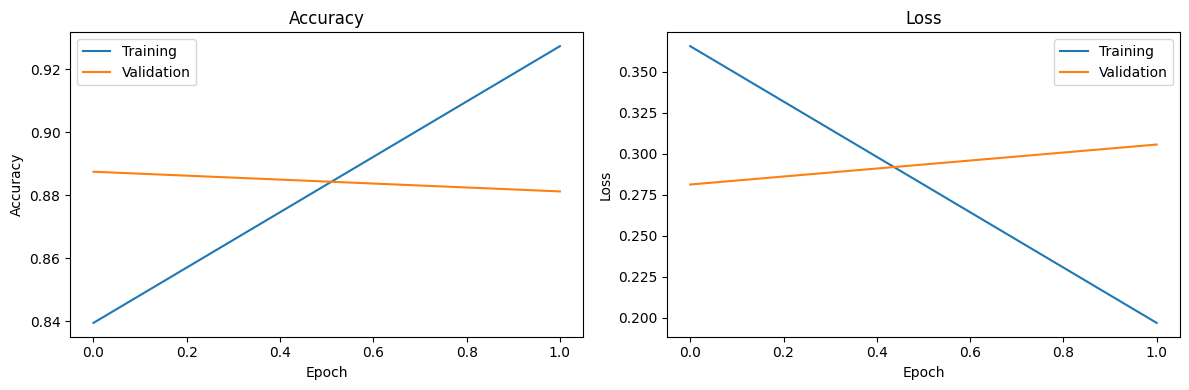

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"], label="Training")
axes[0].plot(history.history["val_accuracy"], label="Validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"], label="Training")
axes[1].plot(history.history["val_loss"], label="Validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 9. Evaluate on the held-out test sample

DistilBERT returns two logits per review. We convert them to positive-class probabilities with softmax and apply a 0.5 decision threshold.

In [30]:
test_logits = model.predict(x_test, batch_size=BATCH_SIZE, verbose=1)
test_probabilities = tf.nn.softmax(test_logits, axis=1).numpy()[:, 1]
y_pred = (test_probabilities >= THRESHOLD).astype(int)

test_accuracy = accuracy_score(y_test, y_pred)
test_roc_auc = roc_auc_score(y_test, test_probabilities)

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test ROC-AUC: {test_roc_auc:.4f}")
print()
print(classification_report(
    y_test,
    y_pred,
    target_names=["Negative", "Positive"],
    digits=4,
    zero_division=0,
))

313/313 ━━━━━━━━━━━━━━━━━━━━ 53s 157ms/step
Test accuracy: 0.8828
Test ROC-AUC: 0.9619

              precision    recall  f1-score   support

    Negative     0.9354    0.8224    0.8753      2500
    Positive     0.8415    0.9432    0.8895      2500

    accuracy                         0.8828      5000
   macro avg     0.8885    0.8828    0.8824      5000
weighted avg     0.8885    0.8828    0.8824      5000



## 9.1 Choose a decision threshold on validation data

The default threshold is 0.5, but the model is weaker on negative reviews, so a different cut-off may balance the two classes better.

To avoid tuning on the test set, the threshold is chosen using the **validation** set only, then applied once to the test set. The criterion is macro-F1, which weights both classes equally.

Caveat: the validation set is small (1,600 reviews), so a small gain from a tuned threshold may just be noise.

In [ ]:
val_logits = model.predict(x_val, batch_size=BATCH_SIZE, verbose=0)
val_probabilities = tf.nn.softmax(val_logits, axis=1).numpy()[:, 1]

candidate_thresholds = np.arange(0.20, 0.801, 0.05)
threshold_table = pd.DataFrame([
    {
        "threshold": round(float(t), 2),
        "val_accuracy": accuracy_score(y_val, (val_probabilities >= t).astype(int)),
        "val_macro_f1": f1_score(y_val, (val_probabilities >= t).astype(int), average="macro"),
    }
    for t in candidate_thresholds
])
BEST_THRESHOLD = float(threshold_table.loc[threshold_table["val_macro_f1"].idxmax(), "threshold"])

print(threshold_table.round(4).to_string(index=False))
print(f"\nSelected threshold (validation macro-F1): {BEST_THRESHOLD}")

## 9.2 Model comparison on the test set

All numbers below are computed on the same 5,000 held-out test reviews. The tuned threshold was picked on validation data only.

In [ ]:
distilbert_default = compute_metrics(y_test, test_probabilities, threshold=THRESHOLD)
distilbert_tuned = compute_metrics(y_test, test_probabilities, threshold=BEST_THRESHOLD)

comparison = pd.DataFrame(
    [baseline_test_metrics, distilbert_default, distilbert_tuned],
    index=["TF-IDF + Logistic Regression", f"DistilBERT (threshold {THRESHOLD})", f"DistilBERT (tuned threshold {BEST_THRESHOLD})"],
).round(4)
comparison.index.name = "model"
comparison.to_csv(OUTPUT_DIR / "model_comparison.csv")
comparison

## 10. Confusion matrix

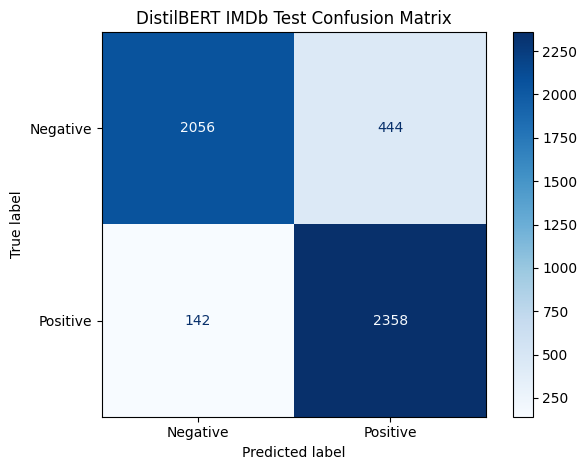

In [33]:
cm = confusion_matrix(y_test, y_pred)
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"],
)
display.plot(cmap="Blues", values_format="d")
plt.title("DistilBERT IMDb Test Confusion Matrix")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Error analysis

Inspect false positives and false negatives, then review high-confidence mistakes. This helps identify examples involving negation, sarcasm, mixed opinions or ambiguous wording.

In [ ]:
from IPython.display import display as show_table

error_rows = []

for idx, (true_label, pred_label, prob) in enumerate(
    zip(y_test, y_pred, test_probabilities)
):
    if true_label != pred_label:
        confidence = max(float(prob), 1.0 - float(prob))
        error_rows.append({
            "true_label": "Positive" if true_label == 1 else "Negative",
            "predicted_label": "Positive" if pred_label == 1 else "Negative",
            "positive_probability": float(prob),
            "confidence": confidence,
            "review": x_test[idx].decode("utf-8"),
        })

errors_df = pd.DataFrame(error_rows)
errors_df.to_csv(OUTPUT_DIR / "misclassified_reviews.csv", index=False)

print("Test reviews:", len(y_test))
print("Misclassified reviews:", len(errors_df))

show_table(errors_df.head(10))

### 11.1 High-confidence incorrect predictions

These are examples where the model was confident but wrong. Inspect them manually rather than treating confidence as correctness.

In [35]:
if not errors_df.empty:
    high_confidence_errors = errors_df.nlargest(20, "confidence")
    high_confidence_errors.to_csv(
        OUTPUT_DIR / "high_confidence_errors.csv", index=False
    )
    show_table(high_confidence_errors[
        ["true_label", "predicted_label", "positive_probability", "confidence", "review"]
    ])
else:
    print("No misclassified reviews in this test sample.")

,true_label,predicted_label,positive_probability,confidence,review
339,Negative,Positive,0.978325,0.978325,? this has to be one of if not the greatest mo...
196,Negative,Positive,0.976820,0.976820,? i really liked this quirky movie the charact...
325,Negative,Positive,0.976643,0.976643,? my friend and i rented this one a few nights...
335,Negative,Positive,0.976606,0.976606,? this film has the language the style and the...
253,Negative,Positive,0.976127,0.976127,? you know i only watched 15 minutes of this f...
32,Negative,Positive,0.974434,0.974434,? the cast of all that returns for good humor ...
231,Negative,Positive,0.973170,0.973170,? i really enjoyed the film it was really chee...
407,Negative,Positive,0.967971,0.967971,? this movie beats everything out there well d...
342,Negative,Positive,0.967212,0.967212,? this movie is truly amazing over the years i...
140,Negative,Positive,0.961958,0.961958,? this story had a good plot to it about four ...


### 11.2 Where do the errors come from?

The review text here is lowercase with no punctuation, so sarcasm can't be detected automatically. Instead, we flag three simple, checkable patterns and compare how often each shows up among errors versus among all test reviews:

- **Negation**: contains words like *not*, *never*, *no*, or a word ending in *n't*
- **Contrast**: contains *but*, *however*, *although*, *though* or *yet* (often a mixed review)
- **Truncated**: longer than the 128-token limit, so part of the review is never seen by DistilBERT

These are rough keyword flags, not a full diagnosis. A category that is over-represented among errors is a lead to investigate, not proof of the cause.

In [36]:
import re

NEGATION_WORDS = {"not", "no", "never", "nothing", "nobody", "hardly", "barely", "without"}
CONTRAST_WORDS = {"but", "however", "although", "though", "yet"}

def flag_review(text):
    words = text.split()
    return {
        "negation": any(w in NEGATION_WORDS or w.endswith("n't") for w in words),
        "contrast": any(w in CONTRAST_WORDS for w in words),
        "truncated": len(words) > MAX_LENGTH,
    }

all_test = pd.DataFrame(
    [flag_review(t.decode("utf-8")) for t in x_test]
)
all_test["is_error"] = (y_test != y_pred)

analysis_rows = []
for flag in ["negation", "contrast", "truncated"]:
    flagged = all_test[all_test[flag]]
    analysis_rows.append({
        "category": flag,
        "share_of_all_reviews": all_test[flag].mean(),
        "share_of_errors": all_test.loc[all_test["is_error"], flag].mean(),
        "error_rate_in_category": flagged["is_error"].mean() if len(flagged) else float("nan"),
    })
analysis_rows.append({
    "category": "all reviews",
    "share_of_all_reviews": 1.0,
    "share_of_errors": 1.0,
    "error_rate_in_category": all_test["is_error"].mean(),
})
error_summary = pd.DataFrame(analysis_rows).round(3)
error_summary.to_csv(OUTPUT_DIR / "error_analysis_summary.csv", index=False)
show_table(error_summary)

# Where do DistilBERT and the TF-IDF baseline disagree?
baseline_pred = (baseline_test_prob >= 0.5).astype(int)
distil_wrong = (y_pred != y_test)
base_wrong = (baseline_pred != y_test)
print("Both wrong:               ", int((distil_wrong & base_wrong).sum()))
print("Only DistilBERT wrong:    ", int((distil_wrong & ~base_wrong).sum()))
print("Only TF-IDF baseline wrong:", int((~distil_wrong & base_wrong).sum()))

# Also look at correct-but-unsure predictions (confidence below 60%)
test_confidence = np.maximum(test_probabilities, 1 - test_probabilities)
low_conf_correct = (~distil_wrong) & (test_confidence < 0.6)
print("Correct but low-confidence (<0.6):", int(low_conf_correct.sum()))

,category,share_of_all_reviews,share_of_errors,error_rate_in_category
0,negation,0.887,0.903,0.119
1,contrast,0.795,0.882,0.130
2,truncated,0.292,0.428,0.172
3,all reviews,1.000,1.000,0.117


Both wrong:                252
Only DistilBERT wrong:     334
Only TF-IDF baseline wrong: 342
Correct but low-confidence (<0.6): 155


**Do this by hand:** read ~20 rows of `high_confidence_errors.csv` and write 3 to 4 observations in the README (for example, "several confident errors are mixed reviews that start positive and end negative"). Only write what you actually see in your own run.

## 12. Try custom movie reviews

The same DistilBERT model accepts raw review strings; its attached preprocessor tokenizes them automatically.

In [37]:
custom_reviews = [
    "This movie was wonderful. The acting was excellent and the story was moving.",
    "The story was boring and the acting was terrible. I would not recommend it.",
]

custom_logits = model.predict(custom_reviews, verbose=0)
custom_probabilities = tf.nn.softmax(custom_logits, axis=1).numpy()

for review, probs in zip(custom_reviews, custom_probabilities):
    predicted_label = int(np.argmax(probs))
    sentiment = "Positive" if predicted_label == 1 else "Negative"
    print("Review:", review)
    print("Predicted sentiment:", sentiment)
    print(f"Positive probability: {probs[1]:.3f}")
    print("-" * 70)

Review: This movie was wonderful. The acting was excellent and the story was moving.
Predicted sentiment: Positive
Positive probability: 0.976
----------------------------------------------------------------------
Review: The story was boring and the acting was terrible. I would not recommend it.
Predicted sentiment: Negative
Positive probability: 0.043
----------------------------------------------------------------------


## 13. Save model and evaluation results

In [38]:
model.save(OUTPUT_DIR / "distilbert_imdb.keras")

metrics = {
    "model": PRESET,
    "train_samples": int(len(x_train)),
    "validation_samples": int(len(x_val)),
    "test_samples": int(len(x_test)),
    "epochs_trained": int(len(history.history["loss"])),
    "max_length": MAX_LENGTH,
    "learning_rate": LEARNING_RATE,
    "threshold_default": THRESHOLD,
    "threshold_tuned_on_validation": BEST_THRESHOLD,
    "test_accuracy": float(test_accuracy),
    "test_roc_auc": float(test_roc_auc),
    "baseline_tfidf_logreg": {k: float(v) for k, v in baseline_test_metrics.items()},
    "distilbert_default_threshold": {k: float(v) for k, v in distilbert_default.items()},
    "distilbert_tuned_threshold": {k: float(v) for k, v in distilbert_tuned.items()},
}

with open(OUTPUT_DIR / "metrics.json", "w", encoding="utf-8") as f:
    json.dump(metrics, f, indent=4)

print("Saved model and metrics in:", OUTPUT_DIR.resolve())
print(metrics)

Saved model and metrics in: /content/outputs
{'model': 'distil_bert_base_en_uncased', 'train_samples': 6400, 'validation_samples': 1600, 'test_samples': 5000, 'epochs_trained': 2, 'max_length': 256, 'learning_rate': 2e-05, 'threshold_default': 0.5, 'threshold_tuned_on_validation': 0.75, 'test_accuracy': 0.8828, 'test_roc_auc': 0.9619020800000001, 'baseline_tfidf_logreg': {'threshold': 0.5, 'accuracy': 0.8812, 'precision': 0.8740188383045526, 'recall': 0.8908, 'f1': 0.8823296354992076, 'negative_recall': 0.8716, 'roc_auc': 0.95247904}, 'distilbert_default_threshold': {'threshold': 0.5, 'accuracy': 0.8828, 'precision': 0.841541755888651, 'recall': 0.9432, 'f1': 0.8894756695586571, 'negative_recall': 0.8224, 'roc_auc': 0.9619020800000001}, 'distilbert_tuned_threshold': {'threshold': 0.75, 'accuracy': 0.8946, 'precision': 0.9101871101871102, 'recall': 0.8756, 'f1': 0.892558613659531, 'negative_recall': 0.9136, 'roc_auc': 0.9619020800000001}}


## 14. Conclusion and limitations

This project demonstrates transfer learning for NLP: a pretrained DistilBERT encoder is fine-tuned for binary sentiment classification, then evaluated with class-wise metrics and error analysis.

**Limitations**
- The first experiment uses a subset of IMDb to keep fine-tuning manageable. The sample sizes are recorded in `metrics.json`.
- Reviews are cut to 128 tokens and rebuilt from word indices (lowercase, no punctuation).
- Results are dependent on the selected sample, training duration and hardware, and come from a single run (no repeated seeds).
- The TF-IDF baseline sees full reviews while DistilBERT sees only the first 128 tokens.
- The error-category flags are simple keyword rules and do not detect sarcasm.
- No hyperparameter search or token-level interpretability was done.
- Custom-review examples are illustrative, not a substitute for a broader external test set.
- No API, web app, Docker or production deployment is included.